In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("seaborn-v0_8")


In [3]:
df = pd.read_csv("../data/cleaned_cafe_sales.csv", parse_dates=["transaction_date"])
df.head()


,transaction_id,item,quantity,price_per_unit,total_spent,payment_method,location,transaction_date,year,month,day_of_week
0,TXN_1961373,Coffee,2.0,20.0,40.0,Credit Card,Takeaway,2023-08-09,2023,8,2
1,TXN_3160411,Coffee,2.0,20.0,40.0,Digital Wallet,In-store,2023-11-06,2023,11,0
2,TXN_4433211,Unknown,3.0,30.0,90.0,Unknown,Takeaway,2023-06-10,2023,6,5
3,TXN_2548360,Salad,5.0,50.0,250.0,Cash,Takeaway,2023-07-11,2023,7,1
4,TXN_7619095,Sandwich,2.0,40.0,80.0,Cash,In-store,2023-03-05,2023,3,6


In [4]:
df.describe()


,quantity,price_per_unit,total_spent,transaction_date,year,month,day_of_week
count,3742.000000,3742.000000,3742.000000,3742,3742.0,3742.000000,3742.000000
mean,3.030999,29.359968,89.172902,2023-06-22 03:36:16.162479872,2023.0,6.504276,3.034206
min,1.000000,10.000000,10.000000,2023-01-01 00:00:00,2023.0,1.000000,0.000000
25%,2.000000,20.000000,40.000000,2023-04-02 00:00:00,2023.0,4.000000,1.000000
50%,3.000000,30.000000,80.000000,2023-06-12 00:00:00,2023.0,6.000000,3.000000
75%,4.000000,40.000000,120.000000,2023-09-11 00:00:00,2023.0,9.000000,5.000000
max,5.000000,50.000000,250.000000,2023-12-12 00:00:00,2023.0,12.000000,6.000000
std,1.390809,12.484068,58.434457,NaN,0.0,3.390610,2.024550


In [5]:
total_revenue = df["total_spent"].sum()
total_revenue


np.float64(333685.0)

In [6]:
avg_ticket = df["total_spent"].mean()
avg_ticket


np.float64(89.17290219134154)

In [7]:
item_sales = (
    df.groupby("item")["total_spent"]
      .sum()
      .sort_values(ascending=False)
)


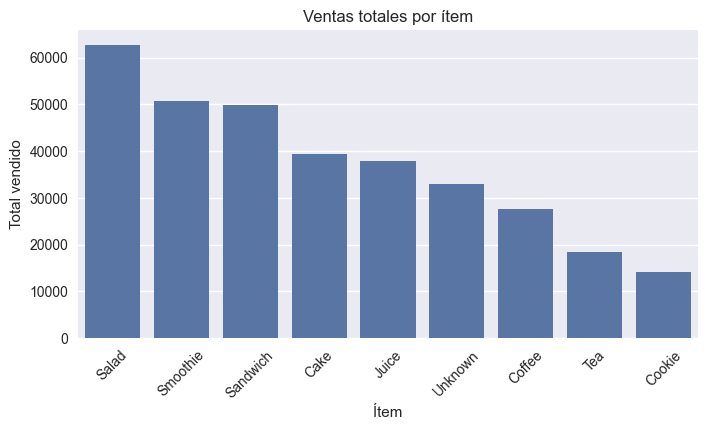

In [8]:
plt.figure(figsize=(8,4))
sns.barplot(x=item_sales.index, y=item_sales.values)
plt.title("Ventas totales por ítem")
plt.ylabel("Total vendido")
plt.xlabel("Ítem")
plt.xticks(rotation=45)
plt.show()


In [9]:
qty_by_item = (
    df.groupby("item")["quantity"]
      .sum()
      .sort_values(ascending=False)
)


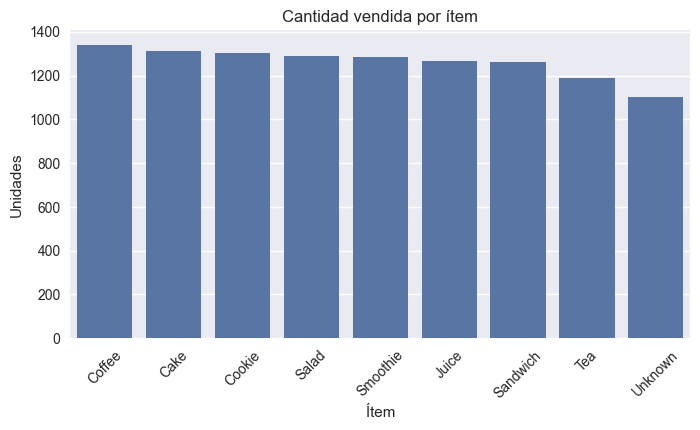

In [10]:
plt.figure(figsize=(8,4))
sns.barplot(x=qty_by_item.index, y=qty_by_item.values)
plt.title("Cantidad vendida por ítem")
plt.ylabel("Unidades")
plt.xlabel("Ítem")
plt.xticks(rotation=45)
plt.show()


In [12]:
monthly_sales = (
    df.groupby("month")["total_spent"]
      .sum()
)


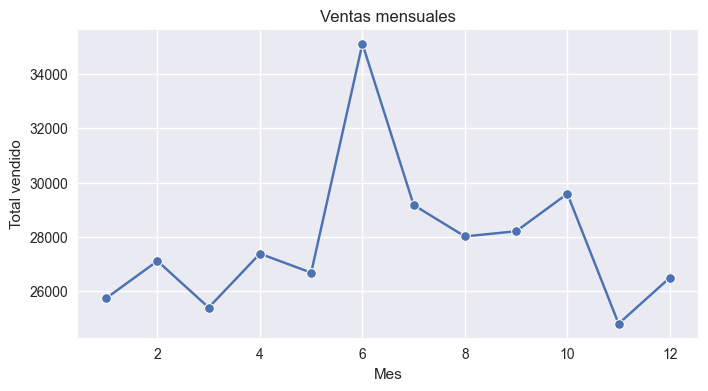

In [13]:
plt.figure(figsize=(8,4))
sns.lineplot(x=monthly_sales.index, y=monthly_sales.values, marker="o")
plt.title("Ventas mensuales")
plt.ylabel("Total vendido")
plt.xlabel("Mes")
plt.show()


In [14]:
payment_dist = df["payment_method"].value_counts(normalize=True) * 100
payment_dist


payment_method
Unknown           31.507215
Digital Wallet    23.196152
Credit Card       22.768573
Cash              22.528060
Name: proportion, dtype: float64

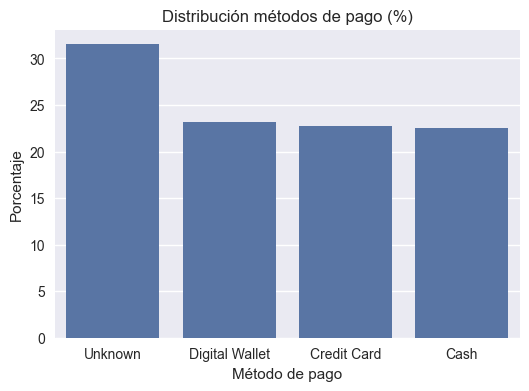

In [15]:
plt.figure(figsize=(6,4))
sns.barplot(x=payment_dist.index, y=payment_dist.values)
plt.title("Distribución métodos de pago (%)")
plt.ylabel("Porcentaje")
plt.xlabel("Método de pago")
plt.show()


In [16]:
location_sales = (
    df.groupby("location")["total_spent"]
      .sum()
)


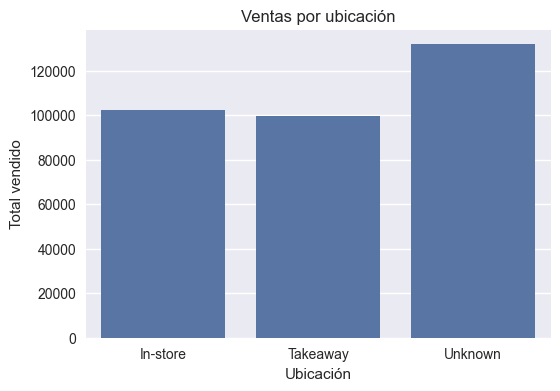

In [17]:
plt.figure(figsize=(6,4))
sns.barplot(x=location_sales.index, y=location_sales.values)
plt.title("Ventas por ubicación")
plt.ylabel("Total vendido")
plt.xlabel("Ubicación")
plt.show()


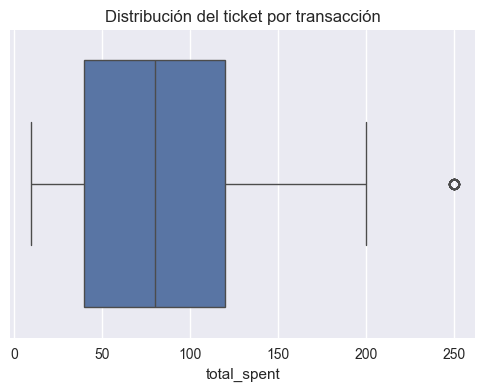

In [18]:
plt.figure(figsize=(6,4))
sns.boxplot(x=df["total_spent"])
plt.title("Distribución del ticket por transacción")
plt.show()
